In [1]:
!pip install astroquery astropy matplotlib numpy pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 55.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 56.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [astroquery]


In [4]:
# Step 1: Import libraries

from astroquery.ipac.irsa import Irsa
from astropy.coordinates import SkyCoord
from astropy import units as u

# Step 2: Select test coordinates

ra_deg = 304.693508808
dec_deg = 42.4436872991

# Step 3: Convert coordinates

coord = SkyCoord(
    ra_deg,
    dec_deg,
    unit="deg"
)

# Step 4: Search radius

search_radius = 1 * u.arcsec

# Step 5: Search NASA SPHEREx

print("Connecting to NASA IRSA...")

results = Irsa.query_sia(
    pos=(coord, search_radius),
    collection=["spherex_dr1", "spherex_qr3"]
)

# Step 6: Display results

print("Successfully connected!")

print("Total images found:", len(results))

# Step 7: Display data

display(results.to_pandas().head(10))

Connecting to NASA IRSA...
Successfully connected!
Total images found: 443


,s_ra,s_dec,facility_name,instrument_name,dataproduct_subtype,calib_level,dataproduct_type,energy_bandpassname,energy_emband,obs_id,...,t_resolution,t_xel,obs_publisher_did,s_fov,em_xel,pol_states,pol_xel,cloud_access,o_ucd,upload_row_id
0,303.877717,40.546690,SPHEREx,SPHEREx,science,2,image,SPHEREx-D1,Infrared,2025W18_1B_0074_2,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0074_2/D1,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
1,303.878447,40.567706,SPHEREx,SPHEREx,science,2,image,SPHEREx-D4,Infrared,2025W18_1B_0074_2,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0074_2/D4,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
2,303.797248,40.733527,SPHEREx,SPHEREx,science,2,image,SPHEREx-D1,Infrared,2025W18_1B_0074_3,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0074_3/D1,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
3,303.797984,40.754557,SPHEREx,SPHEREx,science,2,image,SPHEREx-D4,Infrared,2025W18_1B_0074_3,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0074_3/D4,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
4,303.715555,40.920106,SPHEREx,SPHEREx,science,2,image,SPHEREx-D1,Infrared,2025W18_1B_0074_4,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0074_4/D1,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
5,303.716269,40.941154,SPHEREx,SPHEREx,science,2,image,SPHEREx-D4,Infrared,2025W18_1B_0074_4,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0074_4/D4,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
6,304.232206,43.341194,SPHEREx,SPHEREx,science,2,image,SPHEREx-D1,Infrared,2025W18_1B_0157_1,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0157_1/D1,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
7,304.232222,43.362250,SPHEREx,SPHEREx,science,2,image,SPHEREx-D4,Infrared,2025W18_1B_0157_1,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0157_1/D4,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
8,304.142016,43.526564,SPHEREx,SPHEREx,science,2,image,SPHEREx-D1,Infrared,2025W18_1B_0157_2,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0157_2/D1,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1
9,304.141977,43.547594,SPHEREx,SPHEREx,science,2,image,SPHEREx-D4,Infrared,2025W18_1B_0157_2,...,NaN,<NA>,ivo://irsa.ipac/spherex_dr1?2025W18_1B_0157_2/D4,3.485,<NA>,,<NA>,"{""aws"": {""bucket_name"": ""nasa-irsa-spherex"", ""...",,1


In [8]:
# Step 1: Astropy Table ko Pandas DataFrame mein convert karo
df_results = results.to_pandas()

# Step 2: Check available spectral bands
print("Available SPHEREx Bands:")
print(df_results["energy_bandpassname"].value_counts())

print("\n" + "="*40 + "\n")

# Step 3: Check unique observation IDs
unique_ids = df_results["obs_id"].unique()
print("Total unique observations:", len(unique_ids))
print("\nFirst 10 Observation IDs:")
print(unique_ids[:10])

Available SPHEREx Bands:
energy_bandpassname
SPHEREx-D6    86
SPHEREx-D3    86
SPHEREx-D1    81
SPHEREx-D4    78
SPHEREx-D5    56
SPHEREx-D2    56
Name: count, dtype: int64


Total unique observations: 224

First 10 Observation IDs:
['2025W18_1B_0074_2' '2025W18_1B_0074_3' '2025W18_1B_0074_4'
 '2025W18_1B_0157_1' '2025W18_1B_0157_2' '2025W18_1B_0157_3'
 '2025W18_1B_0157_4' '2025W18_1B_0366_1' '2025W18_1B_0366_2'
 '2025W18_1B_0366_3']


URL: https://irsa.ipac.caltech.edu/ibe/data/spherex/dr1/level2/2025W18_1B/l2b-v27-2026-196/1/level2_2025W18_1B_0074_2D1_spx_l2b-v27-2026-196.fits
Download complete!
Filename: /root/.astropy/cache/download/url/2edb0eda84f44a114b0a0118c29fe067/contents
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       5   ()      
  1  IMAGE         1 ImageHDU       293   (2040, 2040)   float32   
  2  FLAGS         1 CompImageHDU    185   (2040, 2040)   int32   
  3  VARIANCE      1 ImageHDU       119   (2040, 2040)   float32   
  4  ZODI          1 ImageHDU       122   (2040, 2040)   float32   
  5  EPSF          1 BinTableHDU     56   441R x 11C   [J, J, E, E, E, E, J, E, E, E, 1089D]   
  6  WCS-WAVE      1 BinTableHDU     22   1R x 3C   [9J, 9J, 162E]   
Image data shape: (2040, 2040)


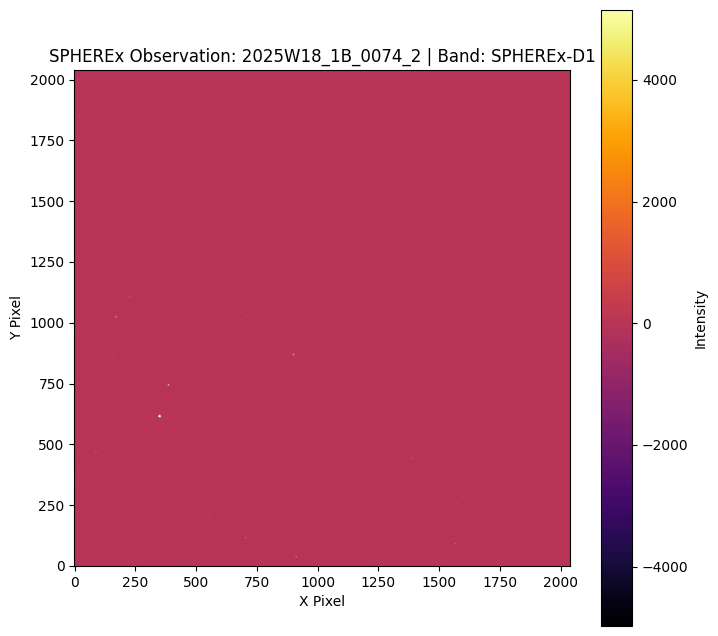

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.utils.data import download_file

# Step 1: DataFrame se pehli observation ka download link (access_url) nikalo
first_row = df_results.iloc[0]
image_url = first_row['access_url']
obs_id = first_row['obs_id']
band = first_row['energy_bandpassname']

print(f"Downloading FITS image for Obs ID: {obs_id} (Band: {band})...")
print(f"URL: {image_url}")

# Step 2: FITS file ko download karo
image_path = download_file(image_url, cache=True, timeout=60)
print("Download complete!")

# Step 3: FITS file ko open karo aur image data read karo
with fits.open(image_path) as hdul:
    hdul.info()  # File ki structure check karne ke liye
    # Aam taur par image data primary ya image extension mein hota hai
    image_data = hdul[0].data
    if image_data is None:
        image_data = hdul[1].data

print("Image data shape:", image_data.shape)

# Step 4: Matplotlib ki madad se image ko screen par display karo
plt.figure(figsize=(8, 8))
# Agar image 2D nahi hai (e.g., 3D ya higher dimension), toh uska pehla slice le lete hain
if image_data.ndim > 2:
    plot_data = image_data[0]
else:
    plot_data = image_data

# Brightness/contrast adjustment ke liye normalization (vmin, vmax)
plt.imshow(plot_data, cmap='inferno', origin='lower')
plt.colorbar(label='Intensity')
plt.title(f"SPHEREx Observation: {obs_id} | Band: {band}")
plt.xlabel("X Pixel")
plt.ylabel("Y Pixel")
plt.show()

In [10]:
from astropy.time import Time
from astropy.visualization import ZScaleInterval

# Step 1: Sirf 'SPHEREx-D1' band ki observations filter karo aur time ke hisab se sort karo
d1_obs = df_results[df_results['energy_bandpassname'] == 'SPHEREx-D1'].sort_values('t_min').reset_index(drop=True)

# MJD time ko human-readable date mein convert karo
d1_obs['obs_date'] = Time(d1_obs['t_min'], format='mjd').iso

print(f"Total SPHEREx-D1 observations: {len(d1_obs)}")
print("\nFirst 5 observations (Earliest):")
display(d1_obs[['obs_id', 'obs_date', 't_min']].head(5))

print("\nLast 5 observations (Latest):")
display(d1_obs[['obs_id', 'obs_date', 't_min']].tail(5))

Total SPHEREx-D1 observations: 81

First 5 observations (Earliest):


,obs_id,obs_date,t_min
0,2025W18_1B_0074_2,2025-04-29 00:24:27.936,60794.016990
1,2025W18_1B_0074_3,2025-04-29 00:26:36.845,60794.018482
2,2025W18_1B_0074_4,2025-04-29 00:28:45.754,60794.019974
3,2025W18_1B_0157_1,2025-04-29 13:25:32.678,60794.559406
4,2025W18_1B_0157_2,2025-04-29 13:27:41.587,60794.560898



Last 5 observations (Latest):


,obs_id,obs_date,t_min
76,2026W23_2A_0205_2,2026-06-05 15:43:36.624,61196.655285
77,2026W23_2A_0205_3,2026-06-05 15:45:45.533,61196.656777
78,2026W23_2A_0205_4,2026-06-05 15:47:54.442,61196.658269
79,2026W24_1A_0511_1,2026-06-10 08:09:28.829,61201.339917
80,2026W24_1A_0511_2,2026-06-10 08:11:37.824,61201.341410


Epoch 1: 2025W18_1B_0074_2 | Date: 2025-04-29 00:24:27.936
Epoch 2: 2026W24_1A_0511_2 | Date: 2026-06-10 08:11:37.824

Dono images successfully load aur clean ho gayi hain!
Epoch 1 Shape: (2040, 2040) | Epoch 2 Shape: (2040, 2040)


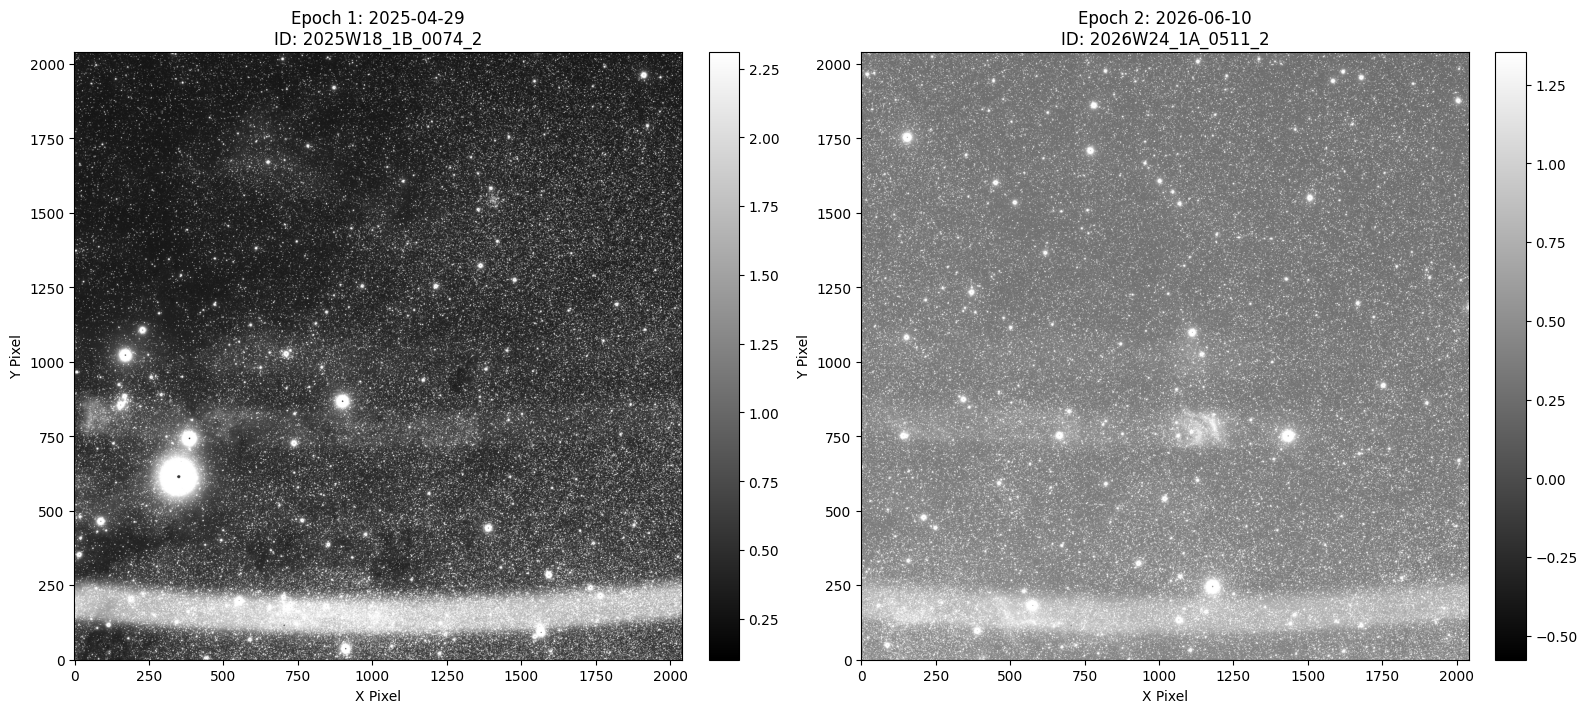

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.utils.data import download_file
from astropy.visualization import ZScaleInterval

# Step 1: Epoch 1 (Earliest) aur Epoch 2 (Latest) select karo
epoch1_row = d1_obs.iloc[0]    # 2025-04-29
epoch2_row = d1_obs.iloc[-1]   # 2026-06-10

print(f"Epoch 1: {epoch1_row['obs_id']} | Date: {epoch1_row['obs_date']}")
print(f"Epoch 2: {epoch2_row['obs_id']} | Date: {epoch2_row['obs_date']}")

# Step 2: Dono FITS files download aur load karne ka function
def load_spherex_image(url):
    path = download_file(url, cache=True, timeout=90)
    with fits.open(path) as hdul:
        img_data = hdul['IMAGE'].data.astype(np.float32)
        header = hdul['IMAGE'].header
    # NaN values ko median se replace karna (data cleaning)
    median_val = np.nanmedian(img_data)
    img_clean = np.nan_to_num(img_data, nan=median_val)
    return img_clean, header, path

img1, hdr1, path1 = load_spherex_image(epoch1_row['access_url'])
img2, hdr2, path2 = load_spherex_image(epoch2_row['access_url'])

print("\nDono images successfully load aur clean ho gayi hain!")
print("Epoch 1 Shape:", img1.shape, "| Epoch 2 Shape:", img2.shape)

# Step 3: Astronomical ZScale normalization (stars ko clearly dikhane ke liye)
zscale = ZScaleInterval()
vmin1, vmax1 = zscale.get_limits(img1)
vmin2, vmax2 = zscale.get_limits(img2)

# Step 4: Side-by-Side Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

im1 = axes[0].imshow(img1, cmap='gray', origin='lower', vmin=vmin1, vmax=vmax1)
axes[0].set_title(f"Epoch 1: {epoch1_row['obs_date'][:10]}\nID: {epoch1_row['obs_id']}")
axes[0].set_xlabel("X Pixel")
axes[0].set_ylabel("Y Pixel")
plt.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)

im2 = axes[1].imshow(img2, cmap='gray', origin='lower', vmin=vmin2, vmax=vmax2)
axes[1].set_title(f"Epoch 2: {epoch2_row['obs_date'][:10]}\nID: {epoch2_row['obs_id']}")
axes[1].set_xlabel("X Pixel")
axes[1].set_ylabel("Y Pixel")
plt.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [12]:
!pip install -q reproject

from astropy.wcs import WCS
from reproject import reproject_interp
import pandas as pd
import os

# Step 1: Dono images ke headers se WCS (World Coordinate System) extract karo
wcs1 = WCS(hdr1)
wcs2 = WCS(hdr2)

print("Aligning Epoch 2 to Epoch 1 sky coordinates (WCS Reprojection)...")

# Step 2: Epoch 2 ko Epoch 1 ke exact pixel-sky grid par reproject karo
img2_aligned, footprint = reproject_interp((img2, wcs2), wcs1, shape_out=img1.shape)

# Reprojection ke baad jo edges bahar reh jayein wahan NaN aa sakta hai, usay clean karo
img2_aligned = np.nan_to_num(img2_aligned, nan=np.nanmedian(img2_aligned))

print("Alignment complete! Dono images ab exact ek hi sky coordinates par aligned hain.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Aligning Epoch 2 to Epoch 1 sky coordinates (WCS Reprojection)...
Alignment complete! Dono images ab exact ek hi sky coordinates par aligned hain.


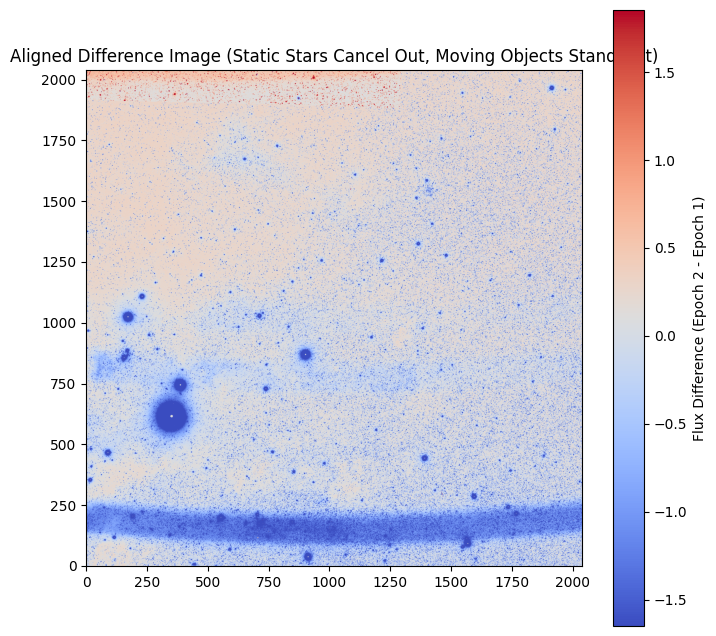


✅ All Handoff Files Successfully Saved in 'SPHEREx_Handoff_Data/'!
['epoch1_aligned.npy', 'epoch2_aligned.npy', 'aligned_difference_preview.png', 'spherex_metadata.csv']


In [13]:
# Create output directory for team handoff
os.makedirs("SPHEREx_Handoff_Data", exist_ok=True)

# 1. Save Aligned Scientific NumPy Arrays (Member 4 ke ML/CV algorithms ke liye)
np.save("SPHEREx_Handoff_Data/epoch1_aligned.npy", img1)
np.save("SPHEREx_Handoff_Data/epoch2_aligned.npy", img2_aligned)

# 2. Save Metadata CSV (Dates, Coordinates, Obs IDs, Band)
metadata = pd.DataFrame([
    {
        "epoch": "Epoch_1",
        "obs_id": epoch1_row['obs_id'],
        "obs_date_utc": epoch1_row['obs_date'],
        "mjd": epoch1_row['t_min'],
        "band": epoch1_row['energy_bandpassname'],
        "ra_deg": epoch1_row['s_ra'],
        "dec_deg": epoch1_row['s_dec'],
        "shape": str(img1.shape),
        "file_name": "epoch1_aligned.npy"
    },
    {
        "epoch": "Epoch_2",
        "obs_id": epoch2_row['obs_id'],
        "obs_date_utc": epoch2_row['obs_date'],
        "mjd": epoch2_row['t_min'],
        "band": epoch2_row['energy_bandpassname'],
        "ra_deg": epoch2_row['s_ra'],
        "dec_deg": epoch2_row['s_dec'],
        "shape": str(img2_aligned.shape),
        "file_name": "epoch2_aligned.npy"
    }
])

metadata.to_csv("SPHEREx_Handoff_Data/spherex_metadata.csv", index=False)

# 3. Quick Difference Map Preview (Sirf verify karne ke liye ke alignment kaisi hui hai)
diff_img = img2_aligned - img1
vmin_d, vmax_d = ZScaleInterval().get_limits(diff_img)

plt.figure(figsize=(8, 8))
plt.imshow(diff_img, cmap='coolwarm', origin='lower', vmin=vmin_d, vmax=vmax_d)
plt.colorbar(label='Flux Difference (Epoch 2 - Epoch 1)')
plt.title("Aligned Difference Image (Static Stars Cancel Out, Moving Objects Stand Out)")
plt.savefig("SPHEREx_Handoff_Data/aligned_difference_preview.png", dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ All Handoff Files Successfully Saved in 'SPHEREx_Handoff_Data/'!")
print(os.listdir("SPHEREx_Handoff_Data"))

In [14]:
import shutil
from google.colab import files

# Folder ko ZIP file mein convert karo
shutil.make_archive("SPHEREx_Data_Lead_Handoff", 'zip', "SPHEREx_Handoff_Data")

# Apne computer par download karo
files.download("SPHEREx_Data_Lead_Handoff.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>